# VLM and Goal-Directed Attention


This notebook analyzes direct VLM outputs (model answers) for both Qwen (Qwen3-VL-32B-Instruct) and Gemma (Gemma-4-26B-A4B-it).

In [93]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [94]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats
from PIL import Image

# analysis/ is the parent of notebooks/
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))
from helpers import runs as R, util as U
U.apply_figstyle()
from helpers.util import gm  # repo-root gaze_metrics
print("data dir:", R.DATA_DIR)
MODELS = ["qwen-instruct", "gemma"]

data dir: /Users/hanzh/Documents/Github/VLM-goal-directed-attention/analysis/data


## Target-Present Images

In [95]:
# Locate the target-present run IDs used for each model and task.
tp_runs = []

for model in MODELS:
    for goal in ["search", "free"]:
        runs = U.get_run_ids(model, condition="tp", goal=goal)
        tp_runs.append({"model": model, "condition": "tp", "goal": goal, "runs": runs})

pd.DataFrame(tp_runs)

,model,condition,goal,runs
0,qwen-instruct,tp,search,"[63889206, 63889207]"
1,qwen-instruct,tp,free,"[63889208, 63889209]"
2,gemma,tp,search,"[64991404, 58387155]"
3,gemma,tp,free,"[58411643, 58387156]"


### Qwen / Model Answer

In [96]:
# Qwen, target-present: read model predictions and human fixations.

# get the run ids
qwen_search_runs = U.get_run_ids("qwen-instruct", condition="tp", goal="search")
qwen_free_runs = U.get_run_ids("qwen-instruct", condition="tp", goal="free")

# get the model predictions
qwen_search_predictions = U.load_fixations(qwen_search_runs, mode="vlm")
qwen_free_predictions = U.load_fixations(qwen_free_runs, mode="vlm")

# get the human fixations
qwen_search_human_fixations = U.load_fixations(qwen_search_runs, mode="human")
qwen_free_human_fixations = U.load_fixations(qwen_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Qwen search | N images:", qwen_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen free | N images:", qwen_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen search human | N images:", qwen_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Qwen free human | N images:", qwen_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Qwen search | N images: 2476
Qwen free | N images: 2476
Qwen search human | N images: 2476
Qwen free human | N images: 2476


In [97]:
qwen_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,0,109,446,152.6,468.3,red bottle on left side of desk,63889206
1,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,1,655,250,917.0,262.5,small container near window,63889206
2,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,2,298,498,417.2,522.9,glass on desk,63889206
3,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,3,875,252,1225.0,264.6,cup near window,63889206
4,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,0,109,446,152.6,468.3,red bottle on left side of desk,63889206


In [98]:
qwen_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000019544.jpg,1400,1050,search,701.4,343.3,63889206
1,bottle,000000019544.jpg,1400,1050,search,974.9,534.9,63889206
2,bottle,000000019544.jpg,1400,1050,search,406.9,525.2,63889206
3,bottle,000000019544.jpg,1400,1050,search,160.1,499.2,63889206
4,bottle,000000019544.jpg,1400,1050,search,158.4,441.9,63889206


In [99]:
# Qwen, target-present: compute density maps per picture.
qwen_search_density_maps = U.density_maps_from_points(
    data=qwen_search_predictions,
    mode="vlm"
)
qwen_free_density_maps = U.density_maps_from_points(
    data=qwen_free_predictions,
    mode="vlm"
)

qwen_search_human_density_maps = U.density_maps_from_points(
    data=qwen_search_human_fixations,
    mode="human",
    goal="search"
)
qwen_free_human_density_maps = U.density_maps_from_points(
    data=qwen_free_human_fixations,
    mode="human",
    goal="free"
)

print("Qwen search maps:", len(qwen_search_density_maps))
print("Qwen free maps:", len(qwen_free_density_maps))
print("Qwen search human maps:", len(qwen_search_human_density_maps))
print("Qwen free human maps:", len(qwen_free_human_density_maps))

Qwen search maps: 2476
Qwen free maps: 2476
Qwen search human maps: 2474
Qwen free human maps: 2476


In [100]:
# Compute per-picture correlations for the Qwen 2x2 comparison.
correlation_rows = []

# get a common set of pictures that exist in all four maps
shared_pictures = sorted(
    set(qwen_search_density_maps)
    & set(qwen_free_density_maps)
    & set(qwen_search_human_density_maps)
    & set(qwen_free_human_density_maps)
)

for target, name in shared_pictures:
    qwen_search_map = qwen_search_density_maps[(target, name)]
    qwen_free_map = qwen_free_density_maps[(target, name)]
    human_search_map = qwen_search_human_density_maps[(target, name)]
    human_free_map = qwen_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", qwen_search_map, human_search_map),
        ("search", "free", qwen_search_map, human_free_map),
        ("free", "search", qwen_free_map, human_search_map),
        ("free", "free", qwen_free_map, human_free_map),
    ]

    for qwen_goal, human_goal, qwen_map, human_map in map_pairs:
        correlation_rows.append(
            {
                "target": target,
                "name": name,
                "qwen_goal": qwen_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(qwen_map, human_map),
            }
        )

qwen_correlations = pd.DataFrame(correlation_rows)
qwen_correlations.head(5)

,target,name,qwen_goal,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.949018
1,bottle,000000001455.jpg,search,free,0.079202
2,bottle,000000001455.jpg,free,search,0.466493
3,bottle,000000001455.jpg,free,free,0.607535
4,bottle,000000009527.jpg,search,search,0.867259


In [101]:
# mean and sd for each group
qwen_correlations.groupby(["qwen_goal", "human_goal"])["correlation"].agg(['mean', 'std']).reset_index()

,qwen_goal,human_goal,mean,std
0,free,free,0.443630,0.171299
1,free,search,0.329111,0.179017
2,search,free,0.161525,0.222598
3,search,search,0.729881,0.181097


In [102]:
# Repeated-measures ANOVA for the Qwen 2x2 design.
qwen_anova_data = qwen_correlations.copy()
qwen_anova_data["picture"] = (
    qwen_anova_data["target"] + " / " + qwen_anova_data["name"]
)

qwen_rmanova = pg.rm_anova(
    data=qwen_anova_data,
    dv="correlation",
    within=["qwen_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_goal,8.709330,1,2473,8.709330,338.472048,6.008002e-71,6.008002e-71,0.023916,1.0
1,human_goal,127.391460,1,2473,127.391460,4243.162330,0.000000e+00,0.000000e+00,0.263832,1.0
2,qwen_goal * human_goal,288.417173,1,2473,288.417173,10334.361228,0.000000e+00,0.000000e+00,0.447938,1.0


In [103]:
# Pairwise tests: compare human_goal within each level of qwen_goal.
pairwise_results = []

for qwen_goal, goal_data in qwen_anova_data.groupby("qwen_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    pairwise_results.append(
        {
            "qwen_goal": qwen_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_pairwise_tests = pd.DataFrame(pairwise_results)
qwen_pairwise_tests[
    ["qwen_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,115.689040,2473,two-sided,0.000000e+00,2.801009,0.559,0.578
1,free,search,free,-24.037794,2473,two-sided,6.414231e-115,0.653642,-0.124,-0.105


/var/folders/gp/95wss1pd2nx0nvwyjlght8p40000gp/T/ipykernel_68123/3776834469.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])


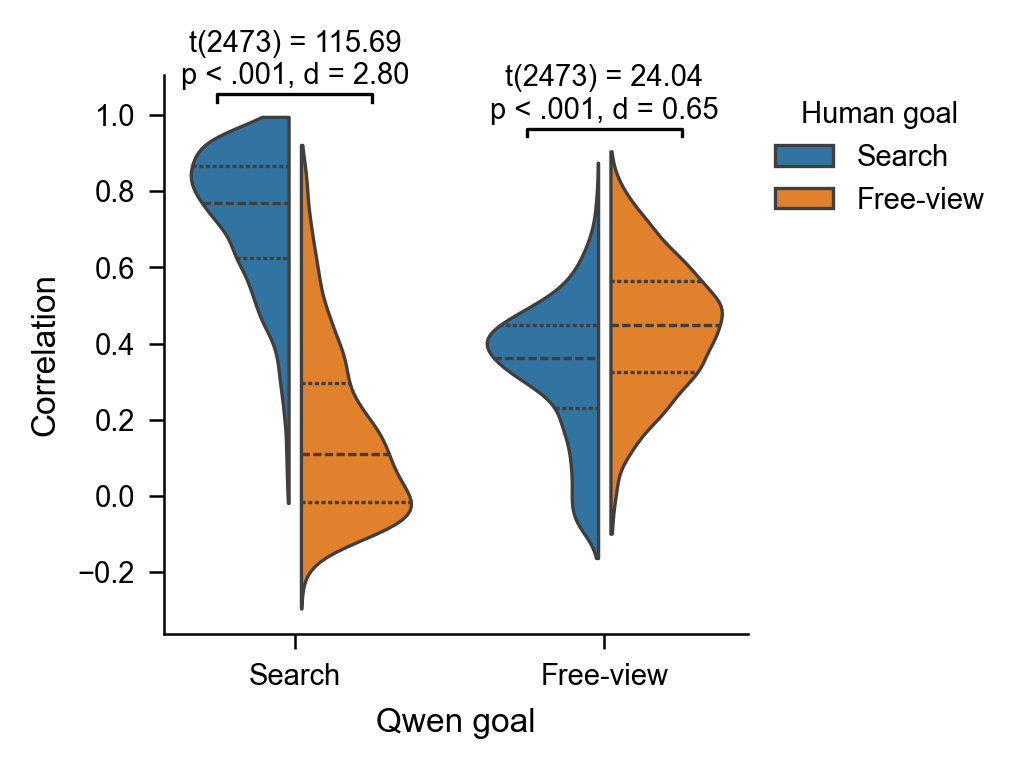

In [104]:
# Violin plot: per-picture correlations for each 2x2 cell.
qwen_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(U.SINGLE_COL, 2.6))
x_positions = np.arange(len(qwen_goal_order))

sns.violinplot(
    data=qwen_correlations,
    x="qwen_goal",
    y="correlation",
    hue="human_goal",
    order=qwen_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_correlations["correlation"].max()
annotation_step = 0.05

for qwen_index, qwen_goal in enumerate(qwen_goal_order):
    pairwise_row = qwen_pairwise_tests[
        qwen_pairwise_tests["qwen_goal"] == qwen_goal
    ].iloc[0]

    x_left = x_positions[qwen_index] - 0.25
    x_right = x_positions[qwen_index] + 0.25
    y_base = qwen_correlations.loc[
        qwen_correlations["qwen_goal"] == qwen_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=7,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen goal")
ax.set_ylabel("Correlation")
ax.set_ylim(top=annotation_top)
ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [U.GOAL_LABEL[l] for l in labels], title="Human goal", loc="best", bbox_to_anchor=(1, 1))
fig.tight_layout()
qwen_violin_fig = fig

### Gemma / Model Answer


In [105]:
# Gemma, target-present: read model predictions and human fixations.

# get the run ids
gemma_search_runs = U.get_run_ids("gemma", condition="tp", goal="search")
gemma_free_runs = U.get_run_ids("gemma", condition="tp", goal="free")

# get the model predictions
gemma_search_predictions = U.load_fixations(gemma_search_runs, mode="vlm")
gemma_free_predictions = U.load_fixations(gemma_free_runs, mode="vlm")

# get the human fixations
gemma_search_human_fixations = U.load_fixations(gemma_search_runs, mode="human")
gemma_free_human_fixations = U.load_fixations(gemma_free_runs, mode="human")

print("Gemma search | N images:", gemma_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma free | N images:", gemma_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma search human | N images:", gemma_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Gemma free human | N images:", gemma_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Gemma search | N images: 2476
Gemma free | N images: 2476
Gemma search human | N images: 2476
Gemma free human | N images: 2476


In [106]:
gemma_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,0,113,449,158.2,471.4,the red bottle on the left,64991404
1,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,1,297,499,415.8,524.0,the glass on the desk,64991404
2,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,2,873,261,1222.2,274.1,the small cup/glass in the background,64991404
3,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,0,111,449,155.4,471.4,the red bottle on the left,64991404
4,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,1,298,500,417.2,525.0,the glass on the desk,64991404


In [107]:
gemma_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000019544.jpg,1400,1050,search,701.4,343.3,64991404
1,bottle,000000019544.jpg,1400,1050,search,974.9,534.9,64991404
2,bottle,000000019544.jpg,1400,1050,search,406.9,525.2,64991404
3,bottle,000000019544.jpg,1400,1050,search,160.1,499.2,64991404
4,bottle,000000019544.jpg,1400,1050,search,158.4,441.9,64991404


In [108]:
# Gemma, target-present: compute density maps per picture.
gemma_search_density_maps = U.density_maps_from_points(
    data=gemma_search_predictions,
    mode="vlm"
)
gemma_free_density_maps = U.density_maps_from_points(
    data=gemma_free_predictions,
    mode="vlm"
)

gemma_search_human_density_maps = U.density_maps_from_points(
    data=gemma_search_human_fixations,
    mode="human",
    goal="search"
)
gemma_free_human_density_maps = U.density_maps_from_points(
    data=gemma_free_human_fixations,
    mode="human",
    goal="free"
)

print("Gemma search maps:", len(gemma_search_density_maps))
print("Gemma free maps:", len(gemma_free_density_maps))
print("Gemma search human maps:", len(gemma_search_human_density_maps))
print("Gemma free human maps:", len(gemma_free_human_density_maps))

Gemma search maps: 2476
Gemma free maps: 2476
Gemma search human maps: 2474
Gemma free human maps: 2476


In [109]:
# Compute per-picture correlations for the Gemma 2x2 comparison.
gemma_correlation_rows = []

# get a common set of pictures that exist in all four maps
gemma_shared_pictures = sorted(
    set(gemma_search_density_maps)
    & set(gemma_free_density_maps)
    & set(gemma_search_human_density_maps)
    & set(gemma_free_human_density_maps)
)

for target, name in gemma_shared_pictures:
    gemma_search_map = gemma_search_density_maps[(target, name)]
    gemma_free_map = gemma_free_density_maps[(target, name)]
    human_search_map = gemma_search_human_density_maps[(target, name)]
    human_free_map = gemma_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", gemma_search_map, human_search_map),
        ("search", "free", gemma_search_map, human_free_map),
        ("free", "search", gemma_free_map, human_search_map),
        ("free", "free", gemma_free_map, human_free_map),
    ]

    for gemma_goal, human_goal, gemma_map, human_map in map_pairs:
        gemma_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "gemma_goal": gemma_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(gemma_map, human_map),
            }
        )

gemma_correlations = pd.DataFrame(gemma_correlation_rows)
gemma_correlations

,target,name,gemma_goal,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.943770
1,bottle,000000001455.jpg,search,free,0.090746
2,bottle,000000001455.jpg,free,search,0.456498
3,bottle,000000001455.jpg,free,free,0.577863
4,bottle,000000009527.jpg,search,search,0.784619
...,...,...,...,...,...
9891,tv,000000579186.jpg,free,free,0.498587
9892,tv,000000580392.jpg,search,search,0.621001
9893,tv,000000580392.jpg,search,free,-0.050271
9894,tv,000000580392.jpg,free,search,0.376406


In [110]:
# mean and sd for each group
gemma_correlations.groupby(["gemma_goal", "human_goal"])["correlation"].agg(['mean', 'std']).reset_index()

,gemma_goal,human_goal,mean,std
0,free,free,0.425986,0.189042
1,free,search,0.306680,0.190163
2,search,free,0.164616,0.223378
3,search,search,0.702977,0.201395


In [111]:
# Repeated-measures ANOVA for the Gemma 2x2 design.
gemma_anova_data = gemma_correlations.copy()
gemma_anova_data["picture"] = (
    gemma_anova_data["target"] + " / " + gemma_anova_data["name"]
)

gemma_rmanova = pg.rm_anova(
    data=gemma_anova_data,
    dv="correlation",
    within=["gemma_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_goal,11.259919,1,2473,11.259919,367.626084,1.672003e-76,1.672003e-76,0.027279,1.0
1,human_goal,108.613032,1,2473,108.613032,3202.533693,0.000000e+00,0.000000e+00,0.212916,1.0
2,gemma_goal * human_goal,267.516949,1,2473,267.516949,9457.192265,0.000000e+00,0.000000e+00,0.399861,1.0


In [112]:
# Pairwise tests: compare human_goal within each level of gemma_goal.
gemma_pairwise_results = []

for gemma_goal, goal_data in gemma_anova_data.groupby("gemma_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_pairwise_results.append(
        {
            "gemma_goal": gemma_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_pairwise_tests = pd.DataFrame(gemma_pairwise_results)
gemma_pairwise_tests[
    ["gemma_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,108.845221,2473,two-sided,0.000000e+00,2.531429,0.529,0.548
1,free,search,free,-23.479016,2473,two-sided,3.231867e-110,0.629238,-0.129,-0.109


/var/folders/gp/95wss1pd2nx0nvwyjlght8p40000gp/T/ipykernel_68123/2326892608.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])


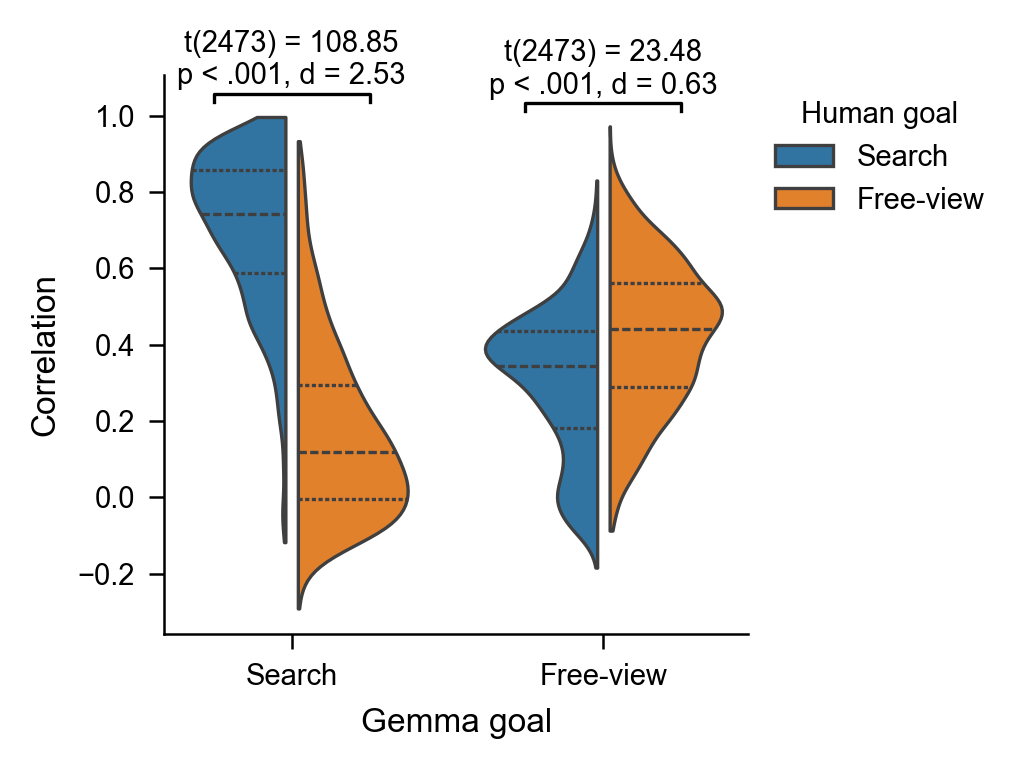

In [113]:
# Violin plot: per-picture correlations for each Gemma 2x2 cell.
gemma_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(U.SINGLE_COL, 2.6))
x_positions = np.arange(len(gemma_goal_order))

sns.violinplot(
    data=gemma_correlations,
    x="gemma_goal",
    y="correlation",
    hue="human_goal",
    order=gemma_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_correlations["correlation"].max()
annotation_step = 0.05

for gemma_index, gemma_goal in enumerate(gemma_goal_order):
    pairwise_row = gemma_pairwise_tests[
        gemma_pairwise_tests["gemma_goal"] == gemma_goal
    ].iloc[0]

    x_left = x_positions[gemma_index] - 0.25
    x_right = x_positions[gemma_index] + 0.25
    y_base = gemma_correlations.loc[
        gemma_correlations["gemma_goal"] == gemma_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=7,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma goal")
ax.set_ylabel("Correlation")
ax.set_ylim(top=annotation_top)
ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [U.GOAL_LABEL[l] for l in labels], title="Human goal", loc="best", bbox_to_anchor=(1, 1))
fig.tight_layout()
gemma_violin_fig = fig

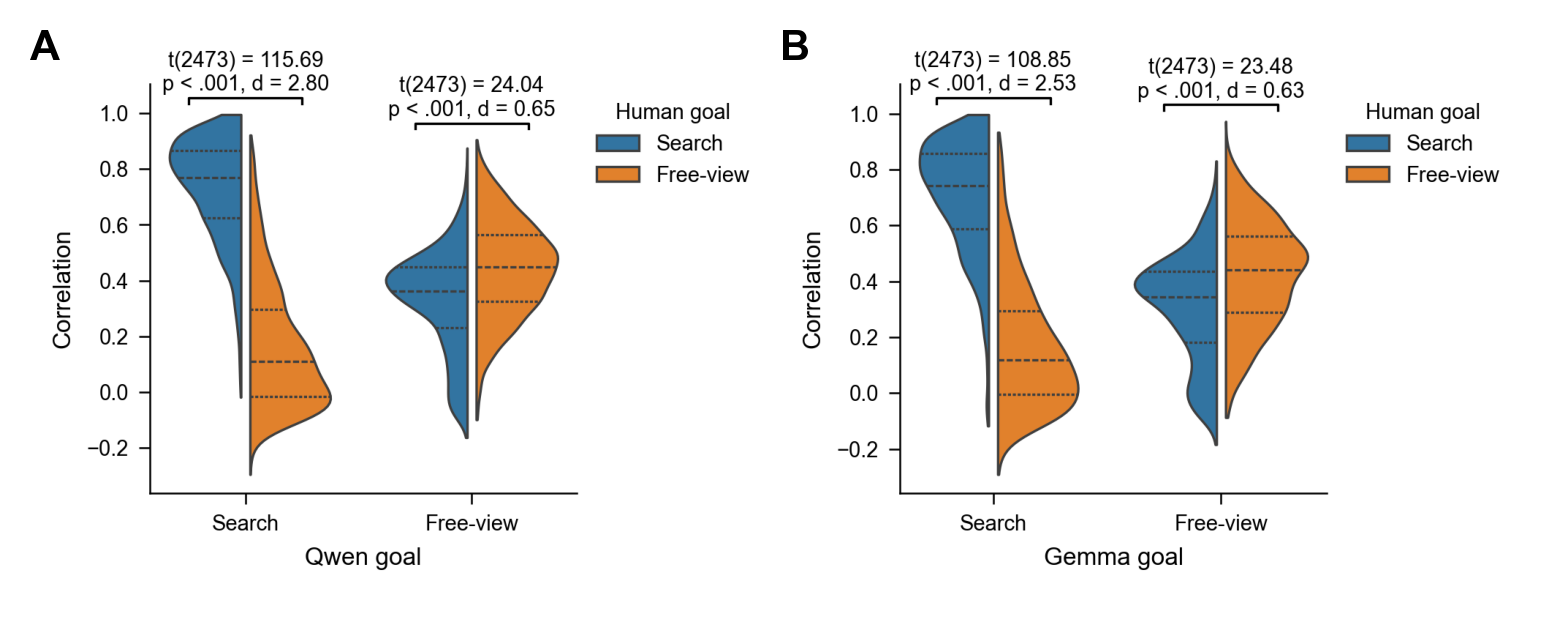

In [114]:
# Stack the already-created Qwen and Gemma violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_violin_image = figure_to_image(qwen_violin_fig)
gemma_violin_image = figure_to_image(gemma_violin_fig)

fig, axes = plt.subplots(1, 2, figsize=(5,10))

for label, ax, image in zip(
    "AB",
    axes,
    [qwen_violin_image, gemma_violin_image],
):
    ax.imshow(image)
    ax.axis("off")
    ax.text(0, 1, label, transform=ax.transAxes, fontsize=10, fontweight="bold", va="top")

fig.tight_layout(pad=0)

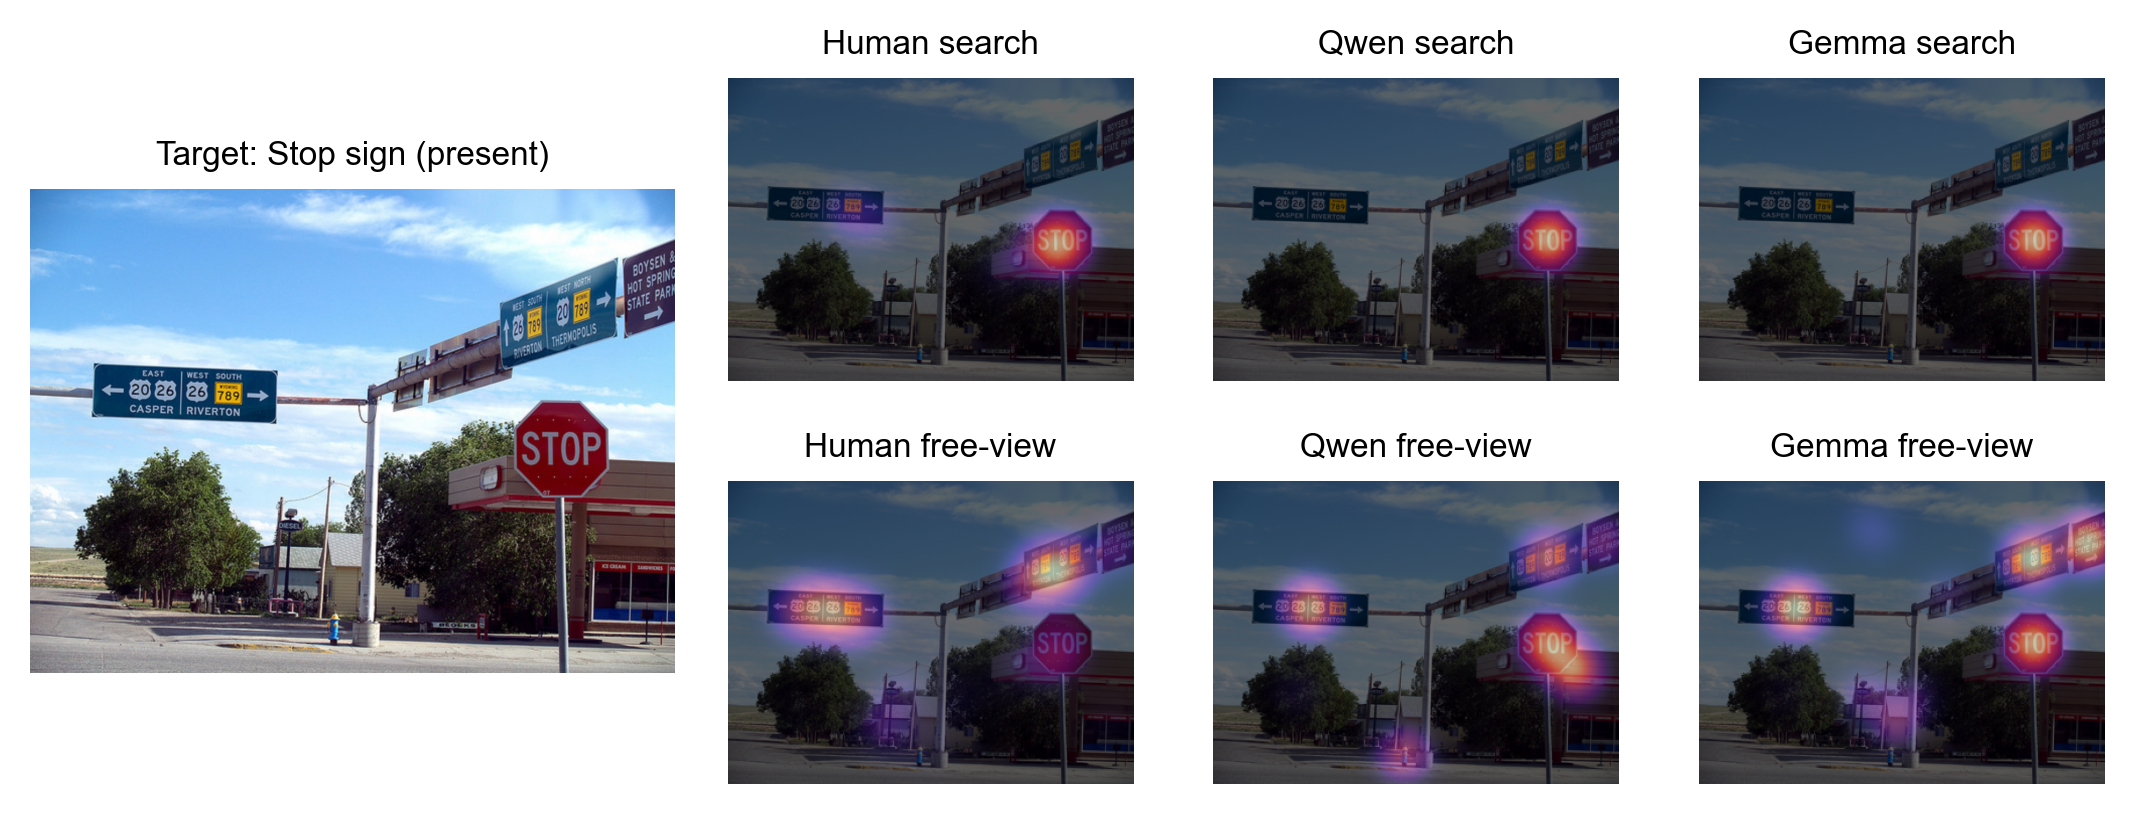

In [115]:
# Plot one example image's density maps for the search/free human and Gemma outputs.
example_picture = ("stop sign", "000000493682.jpg")
example_image_path = ANALYSIS.parent / "data" / "COCO-Search18" / "TP-images" / example_picture[0] / example_picture[1]
example_image = Image.open(example_image_path).convert("RGB")
example_image, _, _ = gm.crop_letterbox(example_image)

example_maps = [
    ("Human search", gemma_search_human_density_maps[example_picture]),
    ("Qwen search", qwen_search_density_maps[example_picture]),
    ("Gemma search", gemma_search_density_maps[example_picture]),
    ("Human free-view", gemma_free_human_density_maps[example_picture]),
    ("Qwen free-view", qwen_free_density_maps[example_picture]),
    ("Gemma free-view", gemma_free_density_maps[example_picture]),
]

fig = plt.figure(figsize=(U.DOUBLE_COL, 2.6), constrained_layout=True)
grid = fig.add_gridspec(
    2,
    4,
    width_ratios=[1.4, 1, 1, 1],
    wspace=0,
    hspace=0,
)

original_ax = fig.add_subplot(grid[:, 0])
original_ax.imshow(example_image)
original_ax.set_title("Target: Stop sign (present)")
original_ax.axis("off")

axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(1, 4)]

for ax, (title, density) in zip(axes, example_maps):
    plot_image = example_image.resize((density.shape[1], density.shape[0]))

    ax.imshow(plot_image, alpha=1)
    ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.6)
    ax.set_title(title)
    ax.axis("off")

## Target-Absent Images


In [116]:
# Locate the target-absent run IDs used for each model and task.
ta_runs = []

for model in MODELS:
    for goal in ["search", "free"]:
        runs = U.get_run_ids(model, condition="ta", goal=goal)
        ta_runs.append({"model": model, "condition": "ta", "goal": goal, "runs": runs})

pd.DataFrame(ta_runs)

,model,condition,goal,runs
0,qwen-instruct,ta,search,"[63889202, 63889203]"
1,qwen-instruct,ta,free,"[63889204, 63889205]"
2,gemma,ta,search,"[64991402, 58387153]"
3,gemma,ta,free,"[64991403, 58387154]"


### Qwen / Model Answer


In [117]:
# Qwen, target-absent: read model predictions and human fixations.
qwen_ta_search_runs = U.get_run_ids("qwen-instruct", condition="ta", goal="search")
qwen_ta_free_runs = U.get_run_ids("qwen-instruct", condition="ta", goal="free")

qwen_ta_search_predictions = U.load_fixations(qwen_ta_search_runs, mode="vlm")
qwen_ta_free_predictions = U.load_fixations(qwen_ta_free_runs, mode="vlm")

qwen_ta_search_human_fixations = U.load_fixations(qwen_ta_search_runs, mode="human")
qwen_ta_free_human_fixations = U.load_fixations(qwen_ta_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Qwen TA search predictions | N images:", qwen_ta_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA free predictions | N images:", qwen_ta_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA search human fixations | N images:", qwen_ta_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA free human fixations | N images:", qwen_ta_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Qwen TA search predictions | N images: 2416
Qwen TA free predictions | N images: 2416
Qwen TA search human fixations | N images: 2416
Qwen TA free human fixations | N images: 2416


In [118]:
qwen_ta_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,0,950,62,1596.0,58.7,glass stemware in upper right corner,63889202
1,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,1,868,52,1458.2,49.2,area near the base of the glass stemware,63889202
2,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,2,923,372,1550.6,352.3,beige napkin area to the right of the bo,63889202
3,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,3,130,219,218.4,207.4,dark surface behind the bowls,63889202
4,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,0,922,54,1549.0,51.1,background area near glassware,63889202


In [119]:
qwen_ta_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000005600.jpg,1680,947,search,1564.9,88.9,63889202
1,bottle,000000005600.jpg,1680,947,search,1461.3,42.3,63889202
2,bottle,000000005600.jpg,1680,947,search,765.0,615.8,63889202
3,bottle,000000005600.jpg,1680,947,search,522.8,520.0,63889202
4,bottle,000000005600.jpg,1680,947,search,1475.8,103.0,63889202


In [120]:
# Qwen, target-absent: compute density maps per picture.
# Reuses shared density-map helpers from helpers.util.
qwen_ta_search_density_maps = U.density_maps_from_points(
    data=qwen_ta_search_predictions,
    mode="vlm"
)
qwen_ta_free_density_maps = U.density_maps_from_points(
    data=qwen_ta_free_predictions,
    mode="vlm"
)

qwen_ta_search_human_density_maps = U.density_maps_from_points(
    data=qwen_ta_search_human_fixations,
    mode="human",
    goal="search"
)
qwen_ta_free_human_density_maps = U.density_maps_from_points(
    data=qwen_ta_free_human_fixations,
    mode="human",
    goal="free"
)

print("Qwen TA search maps:", len(qwen_ta_search_density_maps))
print("Qwen TA free maps:", len(qwen_ta_free_density_maps))
print("Qwen TA search human maps:", len(qwen_ta_search_human_density_maps))
print("Qwen TA free human maps:", len(qwen_ta_free_human_density_maps))

Qwen TA search maps: 2416
Qwen TA free maps: 2416
Qwen TA search human maps: 2413
Qwen TA free human maps: 2416


In [121]:
# Compute per-picture correlations for the Qwen target-absent 2x2 comparison.
qwen_ta_correlation_rows = []

qwen_ta_shared_pictures = sorted(
    set(qwen_ta_search_density_maps)
    & set(qwen_ta_free_density_maps)
    & set(qwen_ta_search_human_density_maps)
    & set(qwen_ta_free_human_density_maps)
)

for target, name in qwen_ta_shared_pictures:
    qwen_search_map = qwen_ta_search_density_maps[(target, name)]
    qwen_free_map = qwen_ta_free_density_maps[(target, name)]
    human_search_map = qwen_ta_search_human_density_maps[(target, name)]
    human_free_map = qwen_ta_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", qwen_search_map, human_search_map),
        ("search", "free", qwen_search_map, human_free_map),
        ("free", "search", qwen_free_map, human_search_map),
        ("free", "free", qwen_free_map, human_free_map),
    ]

    for qwen_goal, human_goal, qwen_map, human_map in map_pairs:
        qwen_ta_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "qwen_goal": qwen_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(qwen_map, human_map),
            }
        )

qwen_ta_correlations = pd.DataFrame(qwen_ta_correlation_rows)
qwen_ta_correlations.head(5)

,target,name,qwen_goal,human_goal,correlation
0,bottle,000000000196.jpg,search,search,0.178551
1,bottle,000000000196.jpg,search,free,-0.086779
2,bottle,000000000196.jpg,free,search,0.148503
3,bottle,000000000196.jpg,free,free,0.294531
4,bottle,000000003992.jpg,search,search,0.648577


In [122]:
# Mean and SD for each target-absent Qwen 2x2 cell.
qwen_ta_correlations.groupby(["qwen_goal", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,qwen_goal,human_goal,mean,std
0,free,free,0.439042,0.163015
1,free,search,0.295048,0.180919
2,search,free,0.234321,0.251272
3,search,search,0.462599,0.236379


In [123]:
# Repeated-measures ANOVA for the Qwen target-absent 2x2 design.
qwen_ta_anova_data = qwen_ta_correlations.copy()
qwen_ta_anova_data["picture"] = (
    qwen_ta_anova_data["target"] + " / " + qwen_ta_anova_data["name"]
)

qwen_ta_rmanova = pg.rm_anova(
    data=qwen_ta_anova_data,
    dv="correlation",
    within=["qwen_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_ta_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_goal,0.833417,1,2412,0.833417,13.961849,1.908887e-04,1.908887e-04,0.001934,1.0
1,human_goal,4.285404,1,2412,4.285404,196.877759,4.715061e-43,4.715061e-43,0.009865,1.0
2,qwen_goal * human_goal,83.601915,1,2412,83.601915,3331.514100,0.000000e+00,0.000000e+00,0.162743,1.0


In [124]:
# Pairwise tests: compare human_goal within each target-absent Qwen goal.
qwen_ta_pairwise_results = []

for qwen_goal, goal_data in qwen_ta_anova_data.groupby("qwen_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    qwen_ta_pairwise_results.append(
        {
            "qwen_goal": qwen_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_ta_pairwise_tests = pd.DataFrame(qwen_ta_pairwise_results)
qwen_ta_pairwise_tests[
    ["qwen_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,47.440230,2412,two-sided,0.000000e+00,0.935799,0.219,0.238
1,free,search,free,-36.356739,2412,two-sided,3.689626e-231,0.836199,-0.152,-0.136


/var/folders/gp/95wss1pd2nx0nvwyjlght8p40000gp/T/ipykernel_68123/743120339.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])


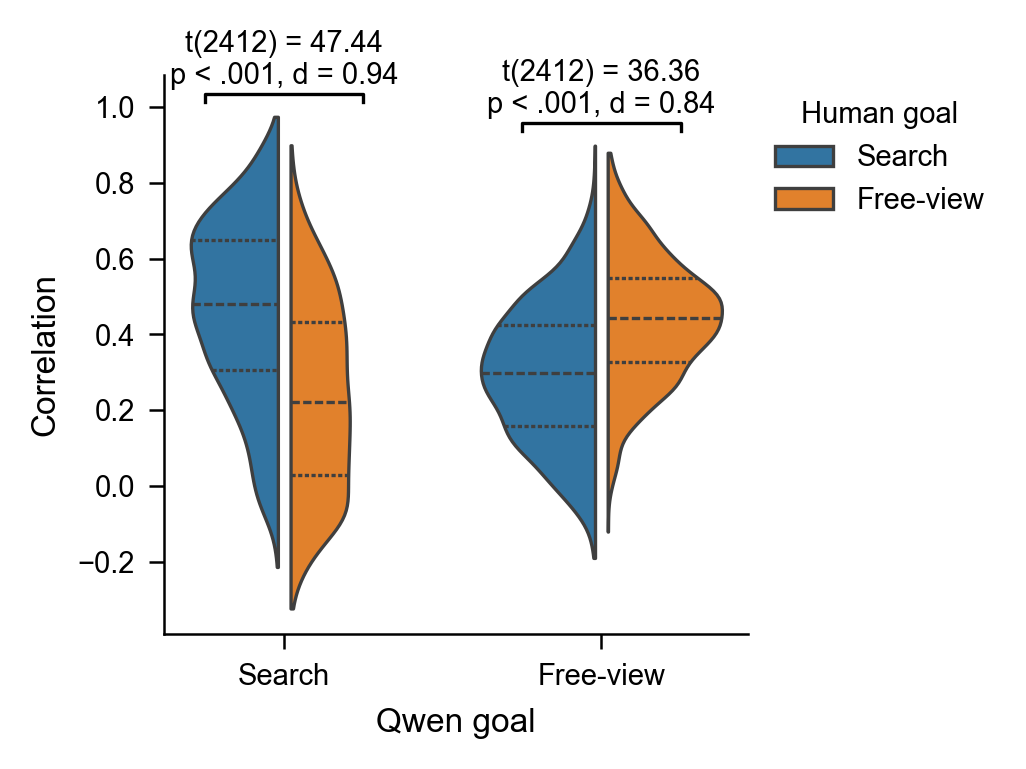

In [138]:
# Violin plot: per-picture correlations for each target-absent Qwen 2x2 cell.
qwen_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(U.SINGLE_COL, 2.6))
x_positions = np.arange(len(qwen_goal_order))

sns.violinplot(
    data=qwen_ta_correlations,
    x="qwen_goal",
    y="correlation",
    hue="human_goal",
    order=qwen_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_ta_correlations["correlation"].max()
annotation_step = 0.05

for qwen_index, qwen_goal in enumerate(qwen_goal_order):
    pairwise_row = qwen_ta_pairwise_tests[
        qwen_ta_pairwise_tests["qwen_goal"] == qwen_goal
    ].iloc[0]

    x_left = x_positions[qwen_index] - 0.25
    x_right = x_positions[qwen_index] + 0.25
    y_base = qwen_ta_correlations.loc[
        qwen_ta_correlations["qwen_goal"] == qwen_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=7,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen goal")
ax.set_ylabel("Correlation")
ax.set_ylim(top=annotation_top)
ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [U.GOAL_LABEL[l] for l in labels], title="Human goal", loc="best", bbox_to_anchor=(1, 1))
fig.tight_layout()
qwen_ta_violin_fig = fig

### Gemma / Model Answer


In [126]:
# Gemma, target-absent: read model predictions and human fixations.
gemma_ta_search_runs = U.get_run_ids("gemma", condition="ta", goal="search")
gemma_ta_free_runs = U.get_run_ids("gemma", condition="ta", goal="free")

gemma_ta_search_predictions = U.load_fixations(gemma_ta_search_runs, mode="vlm")
gemma_ta_free_predictions = U.load_fixations(gemma_ta_free_runs, mode="vlm")

gemma_ta_search_human_fixations = U.load_fixations(gemma_ta_search_runs, mode="human")
gemma_ta_free_human_fixations = U.load_fixations(gemma_ta_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Gemma TA search predictions | N images:", gemma_ta_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA free predictions | N images:", gemma_ta_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA search human fixations | N images:", gemma_ta_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA free human fixations | N images:", gemma_ta_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Gemma TA search predictions | N images: 2367
Gemma TA free predictions | N images: 2416
Gemma TA search human fixations | N images: 2416
Gemma TA free human fixations | N images: 2416


In [127]:
gemma_ta_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,0,858,140,1441.4,132.6,the background area,64991402
1,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,1,951,42,1597.7,39.8,the top right corner,64991402
2,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,2,937,894,1574.2,846.6,the bottom right corner,64991402
3,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,0,950,30,1596.0,28.4,the top right corner area,64991402
4,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,1,950,950,1596.0,899.6,the bottom right corner area,64991402


In [128]:
gemma_ta_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000005600.jpg,1680,947,search,1564.9,88.9,64991402
1,bottle,000000005600.jpg,1680,947,search,1461.3,42.3,64991402
2,bottle,000000005600.jpg,1680,947,search,765.0,615.8,64991402
3,bottle,000000005600.jpg,1680,947,search,522.8,520.0,64991402
4,bottle,000000005600.jpg,1680,947,search,1475.8,103.0,64991402


In [129]:
# Gemma, target-absent: compute density maps per picture.
# Reuses shared density-map helpers from helpers.util.
gemma_ta_search_density_maps = U.density_maps_from_points(
    data=gemma_ta_search_predictions,
    mode="vlm"
)
gemma_ta_free_density_maps = U.density_maps_from_points(
    data=gemma_ta_free_predictions,
    mode="vlm"
)

gemma_ta_search_human_density_maps = U.density_maps_from_points(
    data=gemma_ta_search_human_fixations,
    mode="human",
    goal="search"
)
gemma_ta_free_human_density_maps = U.density_maps_from_points(
    data=gemma_ta_free_human_fixations,
    mode="human",
    goal="free"
)

print("Gemma TA search maps:", len(gemma_ta_search_density_maps))
print("Gemma TA free maps:", len(gemma_ta_free_density_maps))
print("Gemma TA search human maps:", len(gemma_ta_search_human_density_maps))
print("Gemma TA free human maps:", len(gemma_ta_free_human_density_maps))

Gemma TA search maps: 2367
Gemma TA free maps: 2416
Gemma TA search human maps: 2413
Gemma TA free human maps: 2416


In [130]:
# Compute per-picture correlations for the Gemma target-absent 2x2 comparison.
gemma_ta_correlation_rows = []

gemma_ta_shared_pictures = sorted(
    set(gemma_ta_search_density_maps)
    & set(gemma_ta_free_density_maps)
    & set(gemma_ta_search_human_density_maps)
    & set(gemma_ta_free_human_density_maps)
)

for target, name in gemma_ta_shared_pictures:
    gemma_search_map = gemma_ta_search_density_maps[(target, name)]
    gemma_free_map = gemma_ta_free_density_maps[(target, name)]
    human_search_map = gemma_ta_search_human_density_maps[(target, name)]
    human_free_map = gemma_ta_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", gemma_search_map, human_search_map),
        ("search", "free", gemma_search_map, human_free_map),
        ("free", "search", gemma_free_map, human_search_map),
        ("free", "free", gemma_free_map, human_free_map),
    ]

    for gemma_goal, human_goal, gemma_map, human_map in map_pairs:
        gemma_ta_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "gemma_goal": gemma_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(gemma_map, human_map),
            }
        )

gemma_ta_correlations = pd.DataFrame(gemma_ta_correlation_rows)
gemma_ta_correlations.head(5)

,target,name,gemma_goal,human_goal,correlation
0,bottle,000000000196.jpg,search,search,-0.087133
1,bottle,000000000196.jpg,search,free,-0.022937
2,bottle,000000000196.jpg,free,search,0.105399
3,bottle,000000000196.jpg,free,free,0.279988
4,bottle,000000003992.jpg,search,search,0.189763


In [131]:
# Mean and SD for each target-absent Gemma 2x2 cell.
gemma_ta_correlations.groupby(["gemma_goal", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,gemma_goal,human_goal,mean,std
0,free,free,0.417362,0.187726
1,free,search,0.269901,0.187349
2,search,free,0.224571,0.239475
3,search,search,0.398029,0.243456


In [132]:
# Repeated-measures ANOVA for the Gemma target-absent 2x2 design.
gemma_ta_anova_data = gemma_ta_correlations.copy()
gemma_ta_anova_data["picture"] = (
    gemma_ta_anova_data["target"] + " / " + gemma_ta_anova_data["name"]
)

gemma_ta_rmanova = pg.rm_anova(
    data=gemma_ta_anova_data,
    dv="correlation",
    within=["gemma_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_ta_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_goal,2.471033,1,2363,2.471033,36.597558,1.683525e-09,1.683525e-09,0.005562,1.0
1,human_goal,0.399428,1,2363,0.399428,17.142228,3.589936e-05,3.589936e-05,0.000903,1.0
2,gemma_goal * human_goal,60.866536,1,2363,60.866536,2371.250696,0.000000e+00,0.000000e+00,0.121091,1.0


In [133]:
# Pairwise tests: compare human_goal within each target-absent Gemma goal.
gemma_ta_pairwise_results = []

for gemma_goal, goal_data in gemma_ta_anova_data.groupby("gemma_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_ta_pairwise_results.append(
        {
            "gemma_goal": gemma_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_ta_pairwise_tests = pd.DataFrame(gemma_ta_pairwise_results)
gemma_ta_pairwise_tests[
    ["gemma_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,35.028021,2363,two-sided,7.188353e-217,0.718332,0.164,0.183
1,free,search,free,-35.862653,2363,two-sided,2.897234e-225,0.786301,-0.156,-0.139


/var/folders/gp/95wss1pd2nx0nvwyjlght8p40000gp/T/ipykernel_68123/4114312503.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])


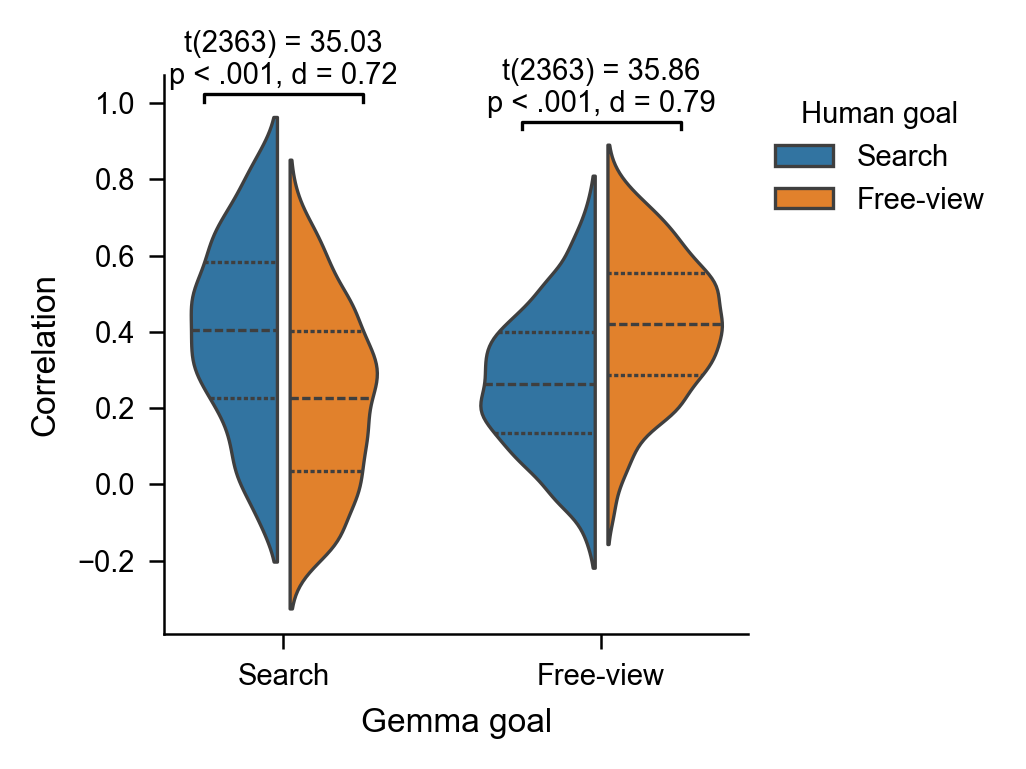

In [137]:
# Violin plot: per-picture correlations for each target-absent Gemma 2x2 cell.
gemma_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(U.SINGLE_COL, 2.6))
x_positions = np.arange(len(gemma_goal_order))

sns.violinplot(
    data=gemma_ta_correlations,
    x="gemma_goal",
    y="correlation",
    hue="human_goal",
    order=gemma_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_ta_correlations["correlation"].max()
annotation_step = 0.05

for gemma_index, gemma_goal in enumerate(gemma_goal_order):
    pairwise_row = gemma_ta_pairwise_tests[
        gemma_ta_pairwise_tests["gemma_goal"] == gemma_goal
    ].iloc[0]

    x_left = x_positions[gemma_index] - 0.25
    x_right = x_positions[gemma_index] + 0.25
    y_base = gemma_ta_correlations.loc[
        gemma_ta_correlations["gemma_goal"] == gemma_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=7,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma goal")
ax.set_ylabel("Correlation")
ax.set_ylim(top=annotation_top)
ax.set_xticklabels([U.GOAL_LABEL[g] for g in human_goal_order])
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [U.GOAL_LABEL[l] for l in labels], title="Human goal", loc="best", bbox_to_anchor=(1, 1))
fig.tight_layout()
gemma_ta_violin_fig = fig

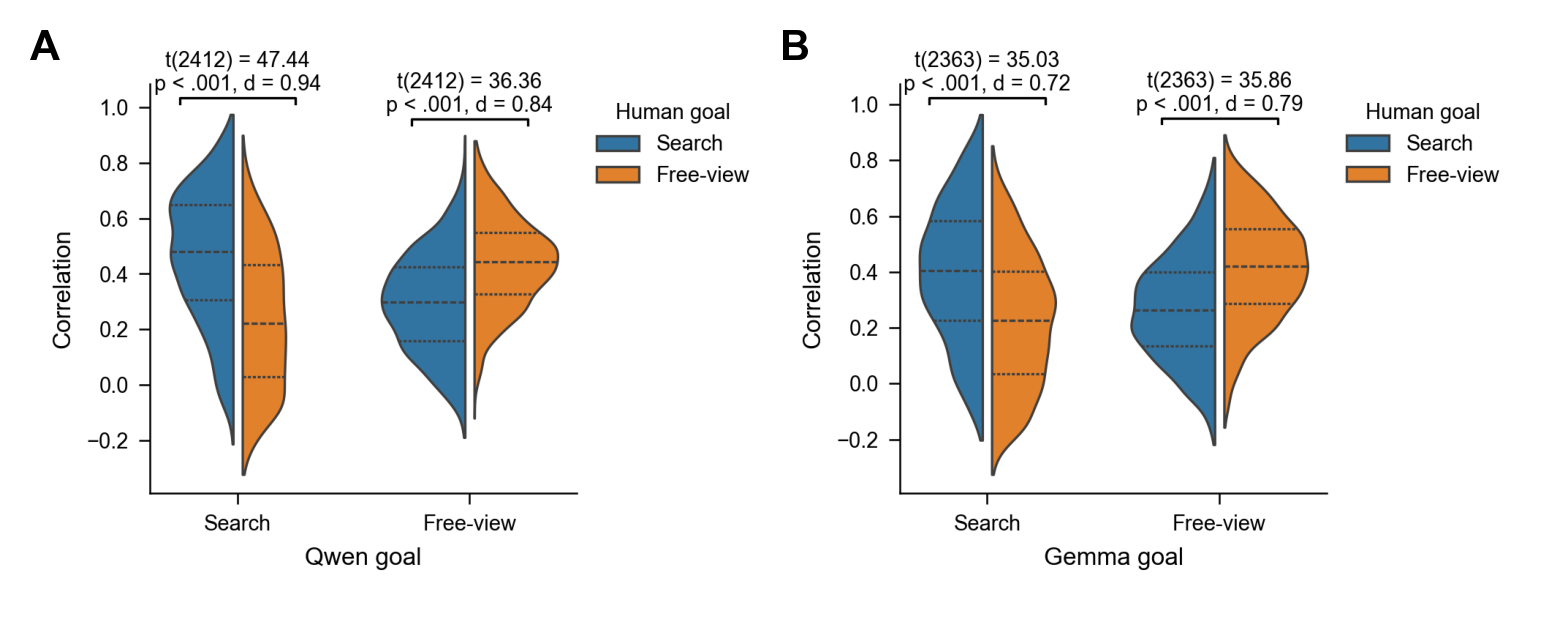

In [139]:
# Stack the already-created target-absent Qwen and Gemma violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_ta_violin_image = figure_to_image(qwen_ta_violin_fig)
gemma_ta_violin_image = figure_to_image(gemma_ta_violin_fig)

fig, axes = plt.subplots(1, 2, figsize=(5, 10))

for label, ax, image in zip(
    "AB",
    axes,
    [qwen_ta_violin_image, gemma_ta_violin_image],
):
    ax.imshow(image)
    ax.axis("off")
    ax.text(0, 1, label, transform=ax.transAxes, fontsize=10, fontweight="bold", va="top")

fig.tight_layout(pad=0)


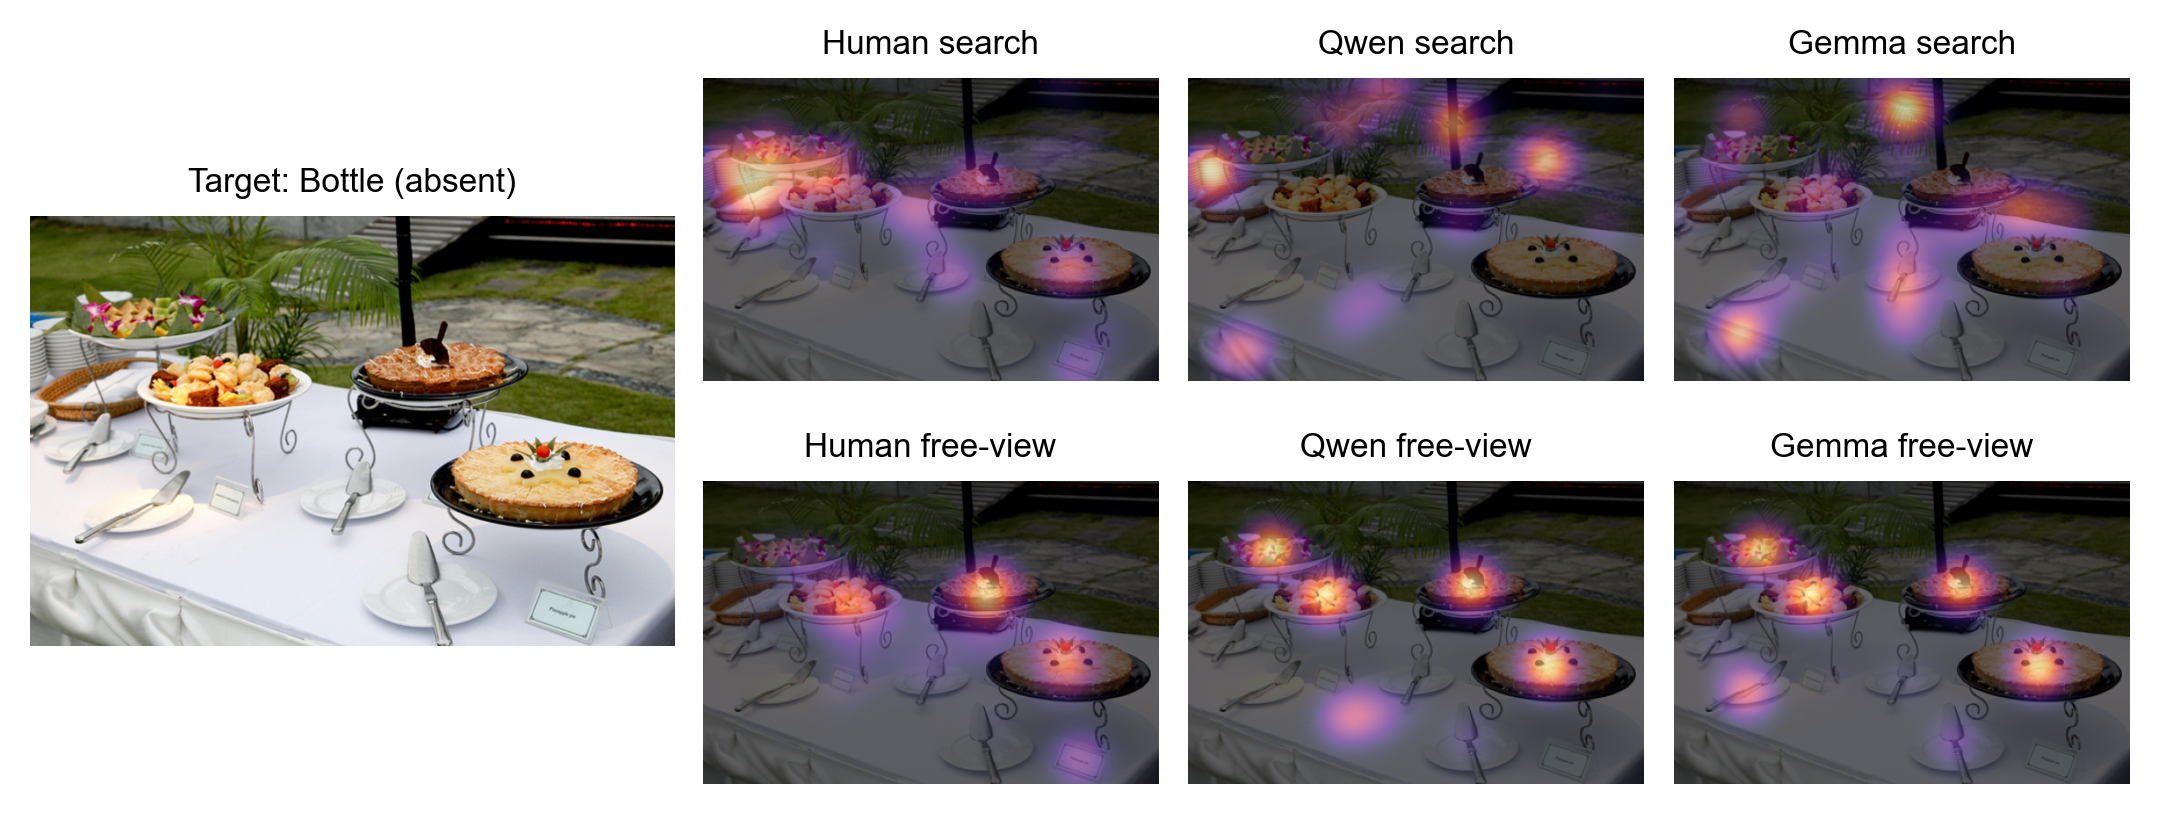

In [136]:
# Plot one representative target-absent image's density maps across humans, Qwen, and Gemma.
ta_example_candidates = sorted(
    set(qwen_ta_search_human_density_maps)
    & set(qwen_ta_free_human_density_maps)
    & set(qwen_ta_search_density_maps)
    & set(qwen_ta_free_density_maps)
    & set(gemma_ta_search_density_maps)
    & set(gemma_ta_free_density_maps)
)

example_picture = ("bottle", "000000085462.jpg")
example_image_path = ANALYSIS.parent / "data" / "COCO-Search18" / "TA-images" / example_picture[0] / example_picture[1]
example_image = Image.open(example_image_path).convert("RGB")
example_image, _, _ = gm.crop_letterbox(example_image)

ta_example_maps = [
    ("Human search", qwen_ta_search_human_density_maps[example_picture]),
    ("Qwen search", qwen_ta_search_density_maps[example_picture]),
    ("Gemma search", gemma_ta_search_density_maps[example_picture]),
    ("Human free-view", qwen_ta_free_human_density_maps[example_picture]),
    ("Qwen free-view", qwen_ta_free_density_maps[example_picture]),
    ("Gemma free-view", gemma_ta_free_density_maps[example_picture]),
]

fig = plt.figure(figsize=(U.DOUBLE_COL, 2.6), constrained_layout=True)
grid = fig.add_gridspec(
    2,
    4,
    width_ratios=[1.4, 1, 1, 1],
    wspace=0,
    hspace=0,
)

original_ax = fig.add_subplot(grid[:, 0])
original_ax.imshow(example_image)
original_ax.set_title("Target: Bottle (absent)")
original_ax.axis("off")

axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(1, 4)]

for ax, (title, density) in zip(axes, ta_example_maps):
    plot_image = example_image.resize((density.shape[1], density.shape[0]))

    ax.imshow(plot_image, alpha=1)
    ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.6)
    ax.set_title(title)
    ax.axis("off")